# Twin structured notes: hedging a digital coupon with event contracts or with options

**Objective:** this is the main empirical part of my Graduating Project: *how do structured notes collateralized by prediction market contracts compare to notes hedged with traditional options in terms of basis risk, maximum drawdown and return on equity, in high and low volatility?*

We build **twin notes**: the same promise to the investor, hedged in three different ways, and we run them every day from March 2024 to October 2026.

**The note.** Every day the investor buys a digital coupon: 1.000 dollars if Bitcoin (CF Benchmarks index, the Kalshi settlement) closes above K at 5 pm New York the next day, with K the Kalshi strike closest to the spot 24 hours before. The issuer charges the option-implied fair value N(d2) (with DVOL) plus a margin of 4 cents per dollar of payoff (about 8% of the price of a digital at the money; Part 7 changes it). The issuer is short the digital and hedges it with:

- **A. Event contract:** buys 1.000 Kalshi contracts of the same strike at the ask. Same index, same time: the payoff matches exactly. Kalshi is fully collateralized, the premium is paid upfront.
- **B. Options (static):** buys a call spread K - h / K + h (h = 0.5% of the spot) scaled to pay 1.000 dollars, priced with Black-Scholes and DVOL plus a bid-ask of 1 volatility point per leg. The payoff is not exactly the digital (partial payment between the strikes) and it settles on another index (we use the Binance price at the close).
- **C. Delta hedge (dynamic):** no options, the issuer trades Bitcoin perpetual futures every hour with the Black-Scholes delta of the digital, paying 0.05% of fees per trade and posting 10% of the futures notional as margin.

**What we measure:** the basis risk in layers (price, payoff and execution), the daily P&L, the maximum drawdown (realised and with a stationary bootstrap), the expected shortfall, and the return on equity under two capital rules (full collateral and margin plus a risk buffer), separately in high and low volatility regimes from a Markov-switching model.

**Data:** Kalshi KXBTCD hourly bid/ask and settlements, Deribit DVOL, Binance BTCUSDT hourly prices.

Libraries of the project: `pandas`, `numpy`, `scipy`, `statsmodels`, `arch`, `matplotlib` and `seaborn`.

## Part 1. Libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from arch.bootstrap import StationaryBootstrap

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

velas = pd.read_parquet("data/kalshi_btc/candles_hourly.parquet")
mercados = pd.read_csv("data/kalshi_btc/markets.csv")
spot = pd.read_parquet("data/kalshi_btc/binance_btcusdt_1h.parquet")[["ts", "close"]].rename(columns={"close": "spot"})
dvol = pd.read_parquet("data/kalshi_btc/deribit_dvol_1h.parquet")
spot["ts"] = pd.to_datetime(spot["ts"], utc=True)
dvol["ts"] = pd.to_datetime(dvol["ts"], utc=True)
S = spot.set_index("ts")["spot"]
V = dvol.set_index("ts")["dvol"] / 100

k = velas.merge(mercados[["ticker", "event_ticker", "strike", "result", "close_time", "expiration_value"]], on="ticker")
k["ts"] = pd.to_datetime(k["ts"], unit="s", utc=True)
k["close_time"] = pd.to_datetime(k["close_time"], utc=True)
k["hours_before"] = ((k["close_time"] - k["ts"]).dt.total_seconds() / 3600).round().astype(int)

NOMINAL = 1000          # dollars paid by the digital coupon
MARGEN = 0.04           # issuer margin per dollar of digital
H = 0.005               # half width of the call spread, share of the spot
VOL_SPREAD = 0.01       # bid-ask of the options, in volatility (1 point per leg)
FEE_PERP = 0.0005       # fee of the perpetual futures, per trade
IM_PERP = 0.10          # initial margin of the perpetual futures

## Part 2. The daily notes

For each day we take the quotes 24 hours before the close and choose the strike closest to the spot among the ones with a real two-sided quote (spread of 10 cents or less). In the first months of 2024 some days only have quotes like bid 0 / ask 0.99, where no issuer would trade.

In [2]:
inicio = k[k["hours_before"] == 24].merge(spot, on="ts").merge(dvol, on="ts")
inicio = inicio.dropna(subset=["ask", "bid"])
inicio = inicio[(inicio["ask"] > 0) & (inicio["ask"] < 1) & (inicio["ask"] - inicio["bid"]).between(0, 0.10)]
inicio["dist"] = (np.log(inicio["strike"] / inicio["spot"])).abs()
notas = inicio.sort_values("dist").groupby("event_ticker").first().reset_index()
notas = notas[notas["dist"] < 0.01].sort_values("close_time").reset_index(drop=True)
notas["paid"] = (notas["result"] == "yes").astype(float)
print("Days with a note:", len(notas), "| from", notas["close_time"].min().date(), "to", notas["close_time"].max().date())
notas[["event_ticker", "strike", "spot", "bid", "ask", "dvol", "paid"]].head()

Days with a note: 664 | from 2024-05-01 to 2026-10-21


,event_ticker,strike,spot,bid,ask,dvol,paid
0,BTCD-24MAY01-17,59999.99,59958.62,0.44,0.53,61.06,0.0
1,BTCD-24MAY02-17,57249.99,57361.70,0.51,0.56,62.51,1.0
2,BTCD-24MAY03-17,58999.99,58727.45,0.46,0.51,56.07,1.0
3,BTCD-24MAY07-17,63499.99,63308.28,0.43,0.49,55.79,0.0
4,BTCD-24MAY08-17,62999.99,62974.94,0.47,0.53,53.89,0.0


### Prices

Fair value of the digital and the cost of the call spread, with tau = 24 hours.

In [3]:
def call(s, kk, v, tau):
    d1 = (np.log(s / kk) + v ** 2 * tau / 2) / (v * np.sqrt(tau))
    return s * norm.cdf(d1) - kk * norm.cdf(d1 - v * np.sqrt(tau))

def digital(s, kk, v, tau):
    return norm.cdf((np.log(s / kk) - v ** 2 * tau / 2) / (v * np.sqrt(tau)))

tau = 24 / (24 * 365)
v = notas["dvol"] / 100
notas["fair"] = digital(notas["spot"], notas["strike"], v, tau)
notas["price_investor"] = notas["fair"] + MARGEN
h = H * notas["spot"]
# long the lower call at the ask (higher vol), short the upper call at the bid (lower vol)
notas["cost_spread"] = (call(notas["spot"], notas["strike"] - h, v + VOL_SPREAD, tau) - call(notas["spot"], notas["strike"] + h, v - VOL_SPREAD, tau)) / (2 * h)
notas["cost_spread_mid"] = (call(notas["spot"], notas["strike"] - h, v, tau) - call(notas["spot"], notas["strike"] + h, v, tau)) / (2 * h)
notas[["fair", "ask", "bid", "cost_spread", "cost_spread_mid"]].describe().round(4)

,fair,ask,bid,cost_spread,cost_spread_mid
count,664.0000,664.0000,664.0000,664.0000,664.0000
mean,0.4942,0.5211,0.4717,0.5350,0.4943
std,0.0288,0.0481,0.0447,0.0286,0.0286
min,0.3314,0.3000,0.2900,0.3702,0.3327
25%,0.4754,0.4900,0.4500,0.5164,0.4757
50%,0.4940,0.5200,0.4700,0.5348,0.4941
75%,0.5160,0.5500,0.5000,0.5570,0.5160
max,0.6114,0.8900,0.8800,0.6494,0.6105


## Part 3. P&L of the three hedges

Per note of 1.000 dollars. The issuer receives the price from the investor and pays 1.000 dollars if the digital pays.

- **A.** pays the Kalshi ask, receives 1.000 if the contract pays (same event: no payoff basis)
- **B.** pays the spread cost, receives the call spread payoff on the Binance price at the close
- **C.** hourly delta hedge with perpetual futures from 24 hours before to the close

In [4]:
notas["s_close"] = notas["close_time"].map(S)
hh = H * notas["spot"]
notas["payoff_spread"] = np.clip(notas["s_close"] - (notas["strike"] - hh), 0, 2 * hh) / (2 * hh)

# in A the Kalshi payoff and the payment to the investor are the same event, so they cancel
notas["pnl_A"] = NOMINAL * (notas["price_investor"] - notas["ask"])
notas["pnl_B"] = NOMINAL * (notas["price_investor"] - notas["cost_spread"] + notas["payoff_spread"] - notas["paid"])

def delta_hedge(fila):
    horas = pd.date_range(fila["close_time"] - pd.Timedelta(hours=24), fila["close_time"], freq="h")
    s = S.reindex(horas).ffill().values
    vol = V.reindex(horas).ffill().values
    pos, pnl, fees, margen = 0.0, 0.0, 0.0, []
    for i in range(len(horas) - 1):
        t = (len(horas) - 1 - i) / (24 * 365)
        d2 = (np.log(s[i] / fila["strike"]) - vol[i] ** 2 * t / 2) / (vol[i] * np.sqrt(t))
        delta = NOMINAL * norm.pdf(d2) / (s[i] * vol[i] * np.sqrt(t))         # in Bitcoin
        fees += FEE_PERP * abs(delta - pos) * s[i]
        pos = delta
        margen.append(IM_PERP * abs(pos) * s[i])
        pnl += pos * (s[i + 1] - s[i])
    fees += FEE_PERP * abs(pos) * s[-1]
    return pd.Series({"hedge_gain": pnl, "fees_C": fees, "margin_C": np.max(margen)})

notas = pd.concat([notas, notas.apply(delta_hedge, axis=1)], axis=1)
notas["pnl_C"] = NOMINAL * notas["price_investor"] - NOMINAL * notas["paid"] + notas["hedge_gain"] - notas["fees_C"]
notas = notas.dropna(subset=["pnl_B", "pnl_C"])
resumen = notas[["pnl_A", "pnl_B", "pnl_C"]].describe(percentiles=[0.01, 0.05, 0.5, 0.95]).round(2)
resumen

,pnl_A,pnl_B,pnl_C
count,664.00,664.00,664.00
mean,13.09,-3.44,-24.46
std,32.79,154.56,268.57
min,-335.20,-549.86,-1140.73
1%,-57.31,-456.27,-619.47
5%,-33.21,-327.03,-493.03
50%,11.83,-0.84,-11.33
95%,62.94,330.75,421.16
max,117.40,559.85,1202.41


Hedge A has no payoff risk at all: the issuer makes (price charged - Kalshi ask) every day, known at the start. Its only risk is the **price basis**: when the Kalshi ask is above the fair value plus the margin, the issuer loses money on that day for sure.

## Part 4. Basis risk in layers

For each hedge we split the P&L per note in:

- **Price basis:** fair value minus the mid price of the hedge (what the hedge market charges more or less than the options fair value)
- **Execution:** mid minus the price paid (half of the bid-ask)
- **Payoff basis:** payoff of the hedge minus what the issuer pays to the investor (zero for Kalshi, the replication error of the call spread, the discrete rebalancing error and fees of the delta hedge)

In [5]:
notas["kalshi_mid"] = (notas["bid"] + notas["ask"]) / 2
capas = pd.DataFrame({
    "A. event contract": {"price basis": (notas["fair"] - notas["kalshi_mid"]).mean() * NOMINAL,
                          "execution": (notas["kalshi_mid"] - notas["ask"]).mean() * NOMINAL,
                          "payoff basis (mean)": 0.0, "payoff basis (std)": 0.0},
    "B. call spread": {"price basis": (notas["fair"] - notas["cost_spread_mid"]).mean() * NOMINAL,
                       "execution": (notas["cost_spread_mid"] - notas["cost_spread"]).mean() * NOMINAL,
                       "payoff basis (mean)": ((notas["payoff_spread"] - notas["paid"]) * NOMINAL).mean(),
                       "payoff basis (std)": ((notas["payoff_spread"] - notas["paid"]) * NOMINAL).std()},
    "C. delta hedge": {"price basis": 0.0, "execution": -notas["fees_C"].mean(),
                       "payoff basis (mean)": (notas["hedge_gain"] - NOMINAL * (notas["paid"] - notas["fair"])).mean(),
                       "payoff basis (std)": (notas["hedge_gain"] - NOMINAL * (notas["paid"] - notas["fair"])).std()},
}).T
capas["margin charged"] = MARGEN * NOMINAL
capas.round(2)

,price basis,execution,payoff basis (mean),payoff basis (std),margin charged
A. event contract,-2.24,-24.68,0.00,0.00,40.0
B. call spread,-0.12,-40.66,-2.67,154.57,40.0
C. delta hedge,0.00,-49.74,-14.72,267.64,40.0


The table reads in dollars per note of 1.000 dollars. The price basis of the event contract is the wedge of the other notebook of the project (Kalshi vs the options digital) at the money: positive means Kalshi is cheaper than the fair value, negative that it is more expensive. The call spread has a small replication error on average, but a large one in the days where Bitcoin closes just between K - h and K + h. The delta hedge has the biggest payoff risk: a digital close to expiry has an enormous gamma, and hourly rebalancing cannot follow it.

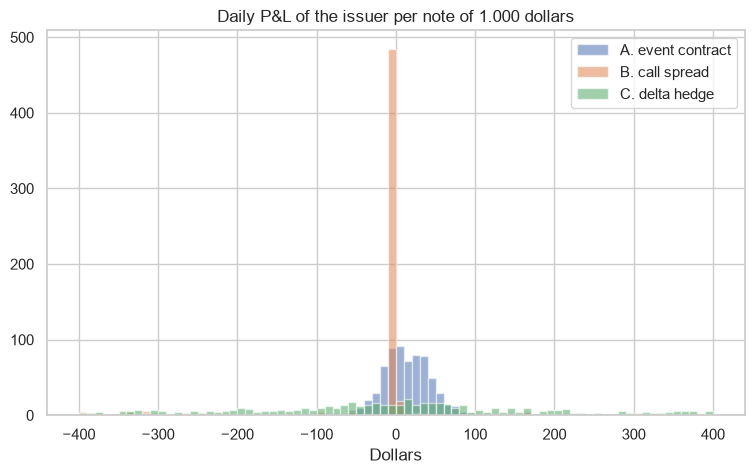

In [6]:
plt.figure(figsize=(9, 5))
for c, nombre in [("pnl_A", "A. event contract"), ("pnl_B", "B. call spread"), ("pnl_C", "C. delta hedge")]:
    plt.hist(notas[c], bins=80, alpha=0.55, label=nombre, range=(-400, 400))
plt.title("Daily P&L of the issuer per note of 1.000 dollars")
plt.xlabel("Dollars")
plt.legend()
plt.savefig("figures/pnl_distribution.png", bbox_inches="tight")
plt.show()

## Part 5. Volatility regimes: Markov switching

A two-state Markov-switching model on the daily Bitcoin returns, with a different variance in each state. The smoothed probability of the high-variance state classifies every day.

Daily volatility of each state (%): [1.56 3.61] | high state: 1
regime
low vol     545
high vol    119
Name: count, dtype: int64


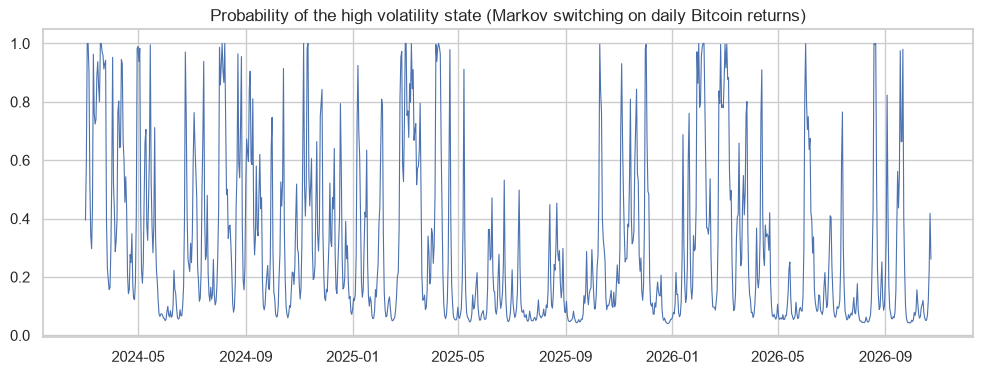

In [7]:
diario = np.log(S).resample("D").last().diff().dropna() * 100
ms = MarkovRegression(diario, k_regimes=2, switching_variance=True).fit(disp=False)
var = ms.params.filter(like="sigma2").values
alto = int(np.argmax(var))
print("Daily volatility of each state (%):", np.sqrt(var).round(2), "| high state:", alto)
p_alto = ms.smoothed_marginal_probabilities[alto]
notas["day"] = notas["close_time"].dt.tz_convert(None).dt.normalize()
p_alto.index = p_alto.index.tz_convert(None).normalize() if p_alto.index.tz is not None else p_alto.index.normalize()
notas["p_high"] = notas["day"].map(p_alto)
notas["regime"] = np.where(notas["p_high"] > 0.5, "high vol", "low vol")
print(notas["regime"].value_counts())

plt.figure(figsize=(12, 4))
plt.plot(p_alto.index, p_alto.values, lw=0.8)
plt.title("Probability of the high volatility state (Markov switching on daily Bitcoin returns)")
plt.savefig("figures/markov_regimes.png", bbox_inches="tight")
plt.show()

## Part 6. Drawdown, expected shortfall and return on equity

We issue one note per day and add up the P&L. **Maximum drawdown** of the cumulative P&L, realised and with a stationary bootstrap of 1-year paths (blocks of 5 days on average, to keep the clusters of volatility). **Expected shortfall** 99% of the daily P&L.

**Return on equity per note** = mean P&L of a note / capital needed to carry it for one day, with two rules (the programme reuses the capital every day, so the annual return is about 365 times this):

1. **Full collateral:** the capital is the money that must be posted to carry the hedge for one day: the Kalshi premium (A), the call spread premium (B), or the futures margin (C)
2. **Collateral plus risk buffer:** the same plus 10 days of 99% expected shortfall, the buffer a risk manager would keep for the residual risk

In [8]:
def max_dd(x):
    c = np.cumsum(x)
    return (np.maximum.accumulate(np.maximum(c, 0)) - c).max()

def es(x, a=0.01):
    x = np.sort(x)
    return -x[: max(int(len(x) * a), 1)].mean()

colateral = {"pnl_A": notas["ask"] * NOMINAL, "pnl_B": notas["cost_spread"] * NOMINAL, "pnl_C": notas["margin_C"]}

def tabla(df, idx):
    filas = []
    for c, nombre in [("pnl_A", "A. event contract"), ("pnl_B", "B. call spread"), ("pnl_C", "C. delta hedge")]:
        x = df[c].values
        cap1 = colateral[c].loc[idx].mean()
        cap2 = cap1 + 10 * es(x)
        filas.append({"hedge": nombre, "days": len(x), "mean_pnl": x.mean(), "std_pnl": x.std(), "es_99": es(x),
                      "max_drawdown": max_dd(x), "annual_pnl": x.mean() * 365,
                      "capital_collateral": cap1, "roe_collateral_%": x.mean() / cap1 * 100,
                      "capital_with_buffer": cap2, "roe_buffer_%": x.mean() / cap2 * 100})
    return pd.DataFrame(filas).set_index("hedge")

total = tabla(notas, notas.index)
total.round(1)

,days,mean_pnl,std_pnl,es_99,max_drawdown,annual_pnl,capital_collateral,roe_collateral_%,capital_with_buffer,roe_buffer_%
hedge,,,,,,,,,,
A. event contract,664,13.1,32.8,118.2,1355.3,4776.7,521.1,2.5,1703.3,0.8
B. call spread,664,-3.4,154.4,496.2,3900.3,-1256.9,535.0,-0.6,5496.5,-0.1
C. delta hedge,664,-24.5,268.4,763.9,19402.9,-8927.9,3990.4,-0.6,11629.2,-0.2


In [9]:
por_regimen = pd.concat({r: tabla(notas[notas["regime"] == r], notas.index[notas["regime"] == r]) for r in ["low vol", "high vol"]})
por_regimen[["days", "mean_pnl", "std_pnl", "es_99", "max_drawdown", "roe_collateral_%", "roe_buffer_%"]].round(1)

days  mean_pnl  std_pnl   es_99  max_drawdown  \
         hedge                                                              
low vol  A. event contract   545      14.5     34.0   126.1        1378.3   
         B. call spread      545      -4.7    166.5   502.5        4021.1   
         C. delta hedge      545     -27.1    278.5   688.5       17673.5   
high vol A. event contract   119       6.6     25.6    78.6         230.1   
         B. call spread      119       2.2     77.7   334.3         494.1   
         C. delta hedge      119     -12.2    215.3  1140.7        3874.8   

                            roe_collateral_%  roe_buffer_%  
         hedge                                              
low vol  A. event contract               2.8           0.8  
         B. call spread                 -0.9          -0.1  
         C. delta hedge                 -0.6          -0.2  
high vol A. event contract               1.3           0.5  
         B. call spread                  0.4           0.1  
         C. delta hedge                 -0.5          -0.1

### Bootstrap of the maximum drawdown

The realised drawdown is one path. With a stationary bootstrap we generate 2.000 paths of one year (365 notes) for each hedge and look at the distribution of the maximum drawdown.

In [10]:
np.random.seed(0)
boot = {}
for c in ["pnl_A", "pnl_B", "pnl_C"]:
    sb = StationaryBootstrap(5, notas[c].values, seed=1)
    dds = []
    for datos, _ in sb.bootstrap(2000):
        dds.append(max_dd(datos[0][:365]))
    boot[c] = np.array(dds)
bt = pd.DataFrame({c: pd.Series(v).describe(percentiles=[0.5, 0.95, 0.99]) for c, v in boot.items()}).T
bt.index = ["A. event contract", "B. call spread", "C. delta hedge"]
bt[["50%", "95%", "99%", "max"]].round(0)

,50%,95%,99%,max
A. event contract,350.0,564.0,710.0,1078.0
B. call spread,3648.0,7090.0,8729.0,11711.0
C. delta hedge,10963.0,17799.0,20625.0,25377.0


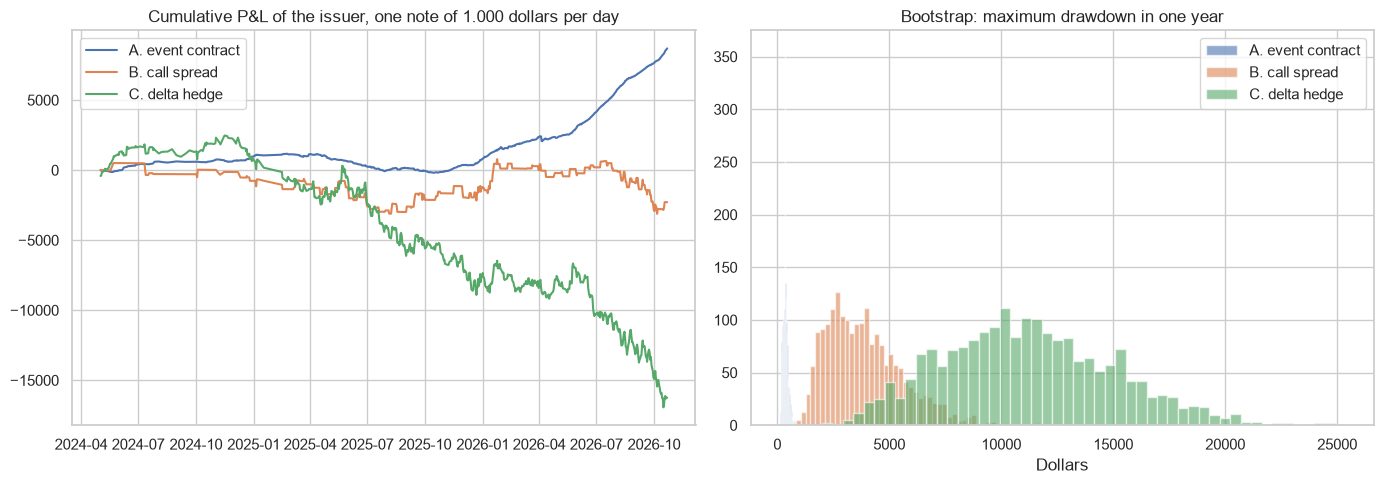

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for c, nombre in [("pnl_A", "A. event contract"), ("pnl_B", "B. call spread"), ("pnl_C", "C. delta hedge")]:
    axes[0].plot(notas["close_time"], notas[c].cumsum(), label=nombre)
    axes[1].hist(boot[c], bins=50, alpha=0.6, label=nombre)
axes[0].set_title("Cumulative P&L of the issuer, one note of 1.000 dollars per day")
axes[0].legend()
axes[1].set_title("Bootstrap: maximum drawdown in one year")
axes[1].set_xlabel("Dollars")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/cumulative_pnl_drawdown.png", bbox_inches="tight")
plt.show()

## Part 7. Sensitivity: the margin of the issuer and the width of the call spread

The results depend on two choices: how much the issuer charges over the fair value, and the width of the call spread (narrow = closer to the digital but more sensitive to the bid-ask).

In [12]:
filas = []
for margen in [0.0, 0.02, 0.04, 0.06, 0.08]:
    for hw in [0.0025, 0.005, 0.01]:
        hh = hw * notas["spot"]
        costo = (call(notas["spot"], notas["strike"] - hh, v.loc[notas.index] + VOL_SPREAD, tau) - call(notas["spot"], notas["strike"] + hh, v.loc[notas.index] - VOL_SPREAD, tau)) / (2 * hh)
        pago = np.clip(notas["s_close"] - (notas["strike"] - hh), 0, 2 * hh) / (2 * hh)
        pa = NOMINAL * (notas["fair"] + margen - notas["ask"])
        pb = NOMINAL * (notas["fair"] + margen - costo + pago - notas["paid"])
        filas.append({"margin": margen, "half_width": hw, "mean_A": pa.mean(), "mean_B": pb.mean(), "std_B": pb.std(),
                      "share_days_A_loses": (pa < 0).mean(), "share_days_B_loses": (pb < 0).mean()})
pd.DataFrame(filas).round(3)

,margin,half_width,mean_A,mean_B,std_B,share_days_A_loses,share_days_B_loses
0,0.00,0.002,-26.913,-80.847,116.181,0.825,0.938
1,0.00,0.005,-26.913,-43.444,154.560,0.825,0.898
2,0.00,0.010,-26.913,-25.955,205.114,0.825,0.803
3,0.02,0.002,-6.913,-60.847,116.181,0.586,0.935
4,0.02,0.005,-6.913,-23.444,154.560,0.586,0.890
5,0.02,0.010,-6.913,-5.955,205.114,0.586,0.417
6,0.04,0.002,13.087,-40.847,116.181,0.340,0.935
7,0.04,0.005,13.087,-3.444,154.560,0.340,0.860
8,0.04,0.010,13.087,14.045,205.114,0.340,0.214
9,0.06,0.002,33.087,-20.847,116.181,0.108,0.932


## Conclusions

Over 664 tradable days (May 2024 to October 2026), one note of 1.000 dollars per day, with a margin of 4 cents per dollar:

| | A. Event contract | B. Call spread | C. Delta hedge |
|---|---|---|---|
| Mean P&L per note (USD) | +13.1 | -3.4 | -24.5 |
| Standard deviation | 32.8 | 154.4 | 268.4 |
| Expected shortfall 99% | 118 | 496 | 764 |
| Realised maximum drawdown | 1.355 | 3.900 | 19.403 |
| Bootstrap 1-year drawdown, median / 99% | 350 / 710 | 3.648 / 8.729 | 10.963 / 20.625 |
| Return on capital per note, collateral / with buffer | 2.5% / 0.8% | -0.6% / -0.1% | -0.6% / -0.2% |

- **Basis risk:** the event contract removes the payoff basis completely (same index, same time), so its only risk is the price paid. The call spread keeps a payoff basis of 155 dollars per note (standard deviation): the days when Bitcoin closes between the two strikes, plus the difference of index. The delta hedge cannot follow the gamma of a digital close to expiry, and its payoff basis is 268 dollars.
- **Drawdown:** with the event contract the drawdown is 10 times smaller than with options, in the realised path and in the bootstrap. For a risk manager this is the main result: the event contract turns the note into a near riskless spread business.
- **Return on equity:** the event contract has the best return with both capital rules. Full collateral is not a big penalty here, because the static option hedge also pays its premium upfront; the delta hedge needs much more margin (the delta of a digital close to the strike is huge) and still loses money.
- **Cost:** the price is the bid-ask. Buying at the Kalshi ask costs around 25 dollars per note, the options spread around 41 and the fees of the delta hedge around 50; the price basis (Kalshi mid against the options fair value) is only about 2 dollars at the money. The event contract breaks even with a margin of about 2.7 cents per dollar.
- **Volatility regimes:** in the high volatility state (119 days) the event contract hedge stays stable (expected shortfall 79), and the call spread works better than in calm days because big moves rarely finish between its strikes. The delta hedge has its worst tail in high volatility (expected shortfall 1.141).
- **Limits:** the options are priced with DVOL and an assumed bid-ask of 1 volatility point, not with real quotes; the notes are one day long, while real notes have longer coupons; and Kalshi depth is not checked here (the liquidity notebook measures how big the notes can be).